# 60장 · 사용자별 장기 기억과 SQL 저장

장기 기억의 값은 대화가 끝난 뒤에도 다시 읽을 수 있습니다. 같은 설정 이름을 여러 사용자가 쓸 때 소유자도 조회 조건에 포함합니다.

첫 대화에서 alice가 답변 언어를 한국어로 저장했습니다. 같은 사용자가 새 대화를 열면 언어를 다시 물을 필요가 없습니다. 반면 같은 이름의 설정을 쓰는 bob에게 이 값이 보이면 안 됩니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 사용자 ID와 설정 키의 복합 조건

메시지는 어느 대화에서 나온 말인지가 중요합니다. 사용자 선호는 새 대화에서도 찾기 위해 사용자와 설정 이름을 함께 키로 삼습니다. 아래는 저장소 조회 범위를 메모리로 재현한 예입니다. PostgreSQL의 영속성은 이 셀에서 측정하지 않습니다.

<!-- lesson-visual visual-key -->
**같은 language 키라도 소유자가 다릅니다**

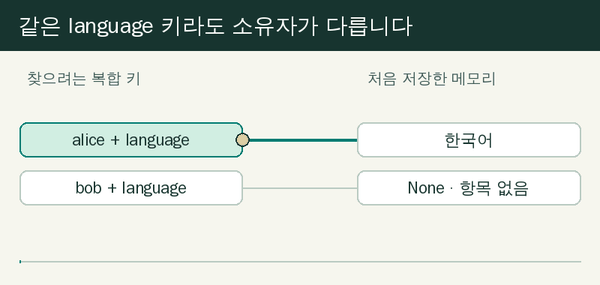

처음에는 alice의 설정만 저장돼 있습니다. 키 이름이 같아도 소유자까지 일치해야 값을 찾으므로 bob을 조회하면 None입니다.
<!-- /lesson-visual visual-key -->


### 셀 01 · 사용자별 설정 키 조회

새 대화 ID 없이도 해당 사용자의 선호를 찾는지 보세요.

설정 키에 사용자 ID는 들어 있지만 대화 ID는 없습니다. 같은 사용자가 대화 A와 B에서 설정을 읽어도 같은 키를 조회합니다. 이 셀이 보여 주는 것은 키의 구성이고, 새 세션 연결은 따로 확인해야 합니다.


In [1]:
memory = {("alice", "language"): "한국어"}
owner = "alice"  # 앱이 확인해 전달한 수업용 사용자
print(memory.get((owner, "language")))

한국어


한국어가 나옵니다. 저장 키에는 대화 ID가 없으므로 다른 대화에서도 사용자의 같은 설정을 읽을 수 있습니다.


### 셀 02 · 동일한 키의 소유자 분리

설정 이름은 그대로 두고 사용자를 바꿉니다.


In [2]:
print(memory.get(("bob", "language")))

None


None은 bob의 항목이 없다는 뜻입니다. 여기서 alice의 값으로 대체하면 사용자 경계가 무너집니다. DB 연결이 끊긴 상황은 조회 성공 후의 빈 값과 따로 처리합니다.


## 선호 정보의 수정과 삭제

실제 수업 구현 memory_service.py의 put은 앱이 건넨 컨텍스트에서 소유자를 읽고 입력 본문에서는 memory_key와 value만 받습니다. 사용자가 보낸 문장으로 소유자를 정하면 다른 사람의 기억에 섞일 수 있습니다.


### 과제 03 · 특정 사용자의 설정 갱신

alice의 값은 유지하고 bob의 언어를 영어로 저장한 뒤 bob의 값을 읽으세요.


In [3]:
# (사용자, 설정 이름) 키로 bob의 값을 저장하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>memory[(&#x27;bob&#x27;, &#x27;language&#x27;)] = &#x27;영어&#x27;
print(memory[(&#x27;bob&#x27;, &#x27;language&#x27;)])</code></pre>
<p>실행 결과</p><pre><code>영어</code></pre>
<p>영어는 bob 행에만 들어갑니다. DB에서는 사용자와 키가 모두 일치하는 행을 수정해야 같은 결과를 얻습니다.</p>
</details>


### 과제 04 · 소유자별 설정 삭제

샘플 복사본에서 alice의 language만 지우고 남은 bob의 설정을 출력하세요.


In [4]:
saved = {('alice', 'language'): '한국어', ('bob', 'language'): '영어'}
# alice의 항목만 지우세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>saved = {(&#x27;alice&#x27;, &#x27;language&#x27;): &#x27;한국어&#x27;, (&#x27;bob&#x27;, &#x27;language&#x27;): &#x27;영어&#x27;}
del saved[(&#x27;alice&#x27;, &#x27;language&#x27;)]
print(saved)</code></pre>
<p>실행 결과</p><pre><code>{(&#x27;bob&#x27;, &#x27;language&#x27;): &#x27;영어&#x27;}</code></pre>
<p>bob의 설정이 남습니다. 저장한 대화 전체를 지운 작업과 별개입니다. 실제 DB에서는 새 연결에서 같은 조회를 반복해 commit이 유지됐는지도 확인합니다.</p>
</details>


## SQL WHERE로 소유자별 조회

제공 PostgreSQL 저장소는 SELECT value FROM course_memories WHERE owner=%s AND memory_key=%s에 (user_id, memory_key)를 따로 전달합니다. 아래는 메모리 SQLite DB에 같은 행을 넣어 조건을 직접 실행하는 실습입니다. 두 드라이버가 쓰는 자리표시자가 다릅니다.


### 셀 05 · SQL 매개변수로 범위 제한

SQLite의 ? 두 자리에 소유자와 설정 이름을 순서대로 전달합니다.


In [5]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE course_memories(owner TEXT, memory_key TEXT, value TEXT, PRIMARY KEY(owner,memory_key))")
db.executemany("INSERT INTO course_memories VALUES (?,?,?)",
               [("alice", "language", "한국어"), ("bob", "language", "영어")])
row = db.execute("SELECT value FROM course_memories WHERE owner=? AND memory_key=?",
                 ("alice", "language")).fetchone()
print(row[0])

한국어


한국어는 두 조건을 모두 만족한 행에서 읽었습니다. PostgreSQL 확인 환경에서는 같은 두 사용자를 준비한 뒤 새 연결에서 조회하고 앱을 재시작해 다시 읽습니다. 이 셀의 메모리 DB는 연결을 닫으면 사라집니다.


## 돌아보기

대화 안에서만 유지할 발화와 다음 대화에서도 필요한 선호를 하나씩 골라 보세요. 새 프로세스에서 읽어야 하는 정보는 이 예제의 메모리 사전만으로 보존할 수 없습니다.
